# Step 1 — Raw Datasets Atlas & Spectral Coverage Audit (`data/00_raw/`)

This notebook provides a step-by-step audit of the **11 spontaneous Raman spectroscopy datasets** (`734,536` valid spectra across `pretrain/` and `downstream/`), organized by spectral regime (`FP`, `HW`, `FR`).

> **Modular Architecture**: Reusable HDF5/MATLAB/NumPy loaders and publication-grade plotting helpers live in `spectrabreast.io.raw_atlas`, keeping every notebook cell concise and focused on a single analytical step.

## 1. Environment Setup & Imports
Import standard scientific libraries and the `spectrabreast.io.raw_atlas` inspection functions.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

from spectrabreast.io.raw_atlas import (
    load_fp_raw_cohorts, load_hw_raw_cohorts, load_fr_raw_cohorts,
    plot_coverage_gantt, plot_fp_raw_grid, plot_hw_raw_grid, plot_fr_raw_grid,
)

ROOT = Path('..').resolve()
RAW_DIR = ROOT / 'data' / '00_raw'
FIG_DIR = ROOT / 'docs' / 'figures' / '01_raw_atlas'

Workspace root: c:\Users\alexf\Desktop\SPECTRA-BREAST
Raw data lake : c:\Users\alexf\Desktop\SPECTRA-BREAST\data\00_raw


## 2. Master Catalog of `data/00_raw/`
Load the master inventory table (`docs/raw_datasets_master_catalog.csv`) and verify total spectrum counts across `pretrain/` (`716,686` spectra) and `downstream/` (`17,850` active validation spectra).

In [2]:
catalog_df = pd.read_csv(ROOT / 'docs' / 'raw_datasets_master_catalog.csv')
cols = ['Folder', 'Dataset', 'Valid Active Spectra', 'Wavenumber Range (cm-1)', 'Channels (Pts)', 'Initial Preprocessing State']
print(f'Catalog entries: {len(catalog_df)} sub-cohorts across 11 dataset folders')
display(catalog_df[cols])

Catalog entries: 13 sub-cohorts across 11 dataset folders


Folder,Dataset,Valid Active Spectra,Wavenumber Range (cm-1),Channels (Pts),Initial Preprocessing State
pretrain/FP,deepr,172312,498.26 - 1799.90,500,Paired Low-SNR (0.1s) & Clean Scaled (1.0s)
pretrain/FP,raman_mae (CELLS),15429,600.46 - 1963.25,871,"Baseline-Subtracted + L2-Normalized (15,429 cell spectra filtered)"
pretrain/FP,raman_mae (TWIST),16496,650.86 - 1749.70,656,"Baseline-Subtracted + L2-Normalized (1,596 zero rows filtered)"
pretrain/FP,raman_mae (IMMUNO),11099,597.32 - 1798.91,721,Baseline-Subtracted + L2-Normalized
pretrain/FP,spectrabreast_fp,52992,660.22 - 1759.36,1015,RAW CCD Detector Counts (needs Despike + ALS + Resampling + MinMax)
pretrain/HW,spectrabreast_hw,136801,2488.85 - 3487.65 (Overlap: 2763.9 - 3258.8),1015,"MIXED: 14 Maps RAW CCD Counts (125,923) + 1 Map SB015HT 2 Post-ALS (10,878)"
pretrain/HW,pdo_hw_maps,194444,2603.29 - 3915.42 (Overlap: 2614.7 - 3906.2),1015,"MIXED: 5 Maps RAW CCD Counts (146,583) + 1 Map CMA64 PDO2 Post-ALS (47,861)"
pretrain/HW,riverd_meat_hw,1200,2520.00 - 4000.00,741,RAW Detector Counts (needs Despike + ALS + Resampling + MinMax)
pretrain/FR,trophy_jena,115913,Raw: 200.0 - 3200.0 | Prep: 648.68 - 3050.44,1024,Both Raw/ (1024 pts) and Preprocessed/ (820 pts) folders available
downstream/FP,ibd,228,403.89 - 1754.26,1216,Baseline-Corrected (patient-averaged from 962 replicates)


## 3. Figure 1 — Global Spectral Coverage Gantt Chart
Visualize the exact wavenumber span ($\text{cm}^{-1}$) of every cohort against the three canonical Raman windows (`FP: 600–1800`, `Silent: 1800–2700`, `HW: 2700–3600` $\text{cm}^{-1}$).

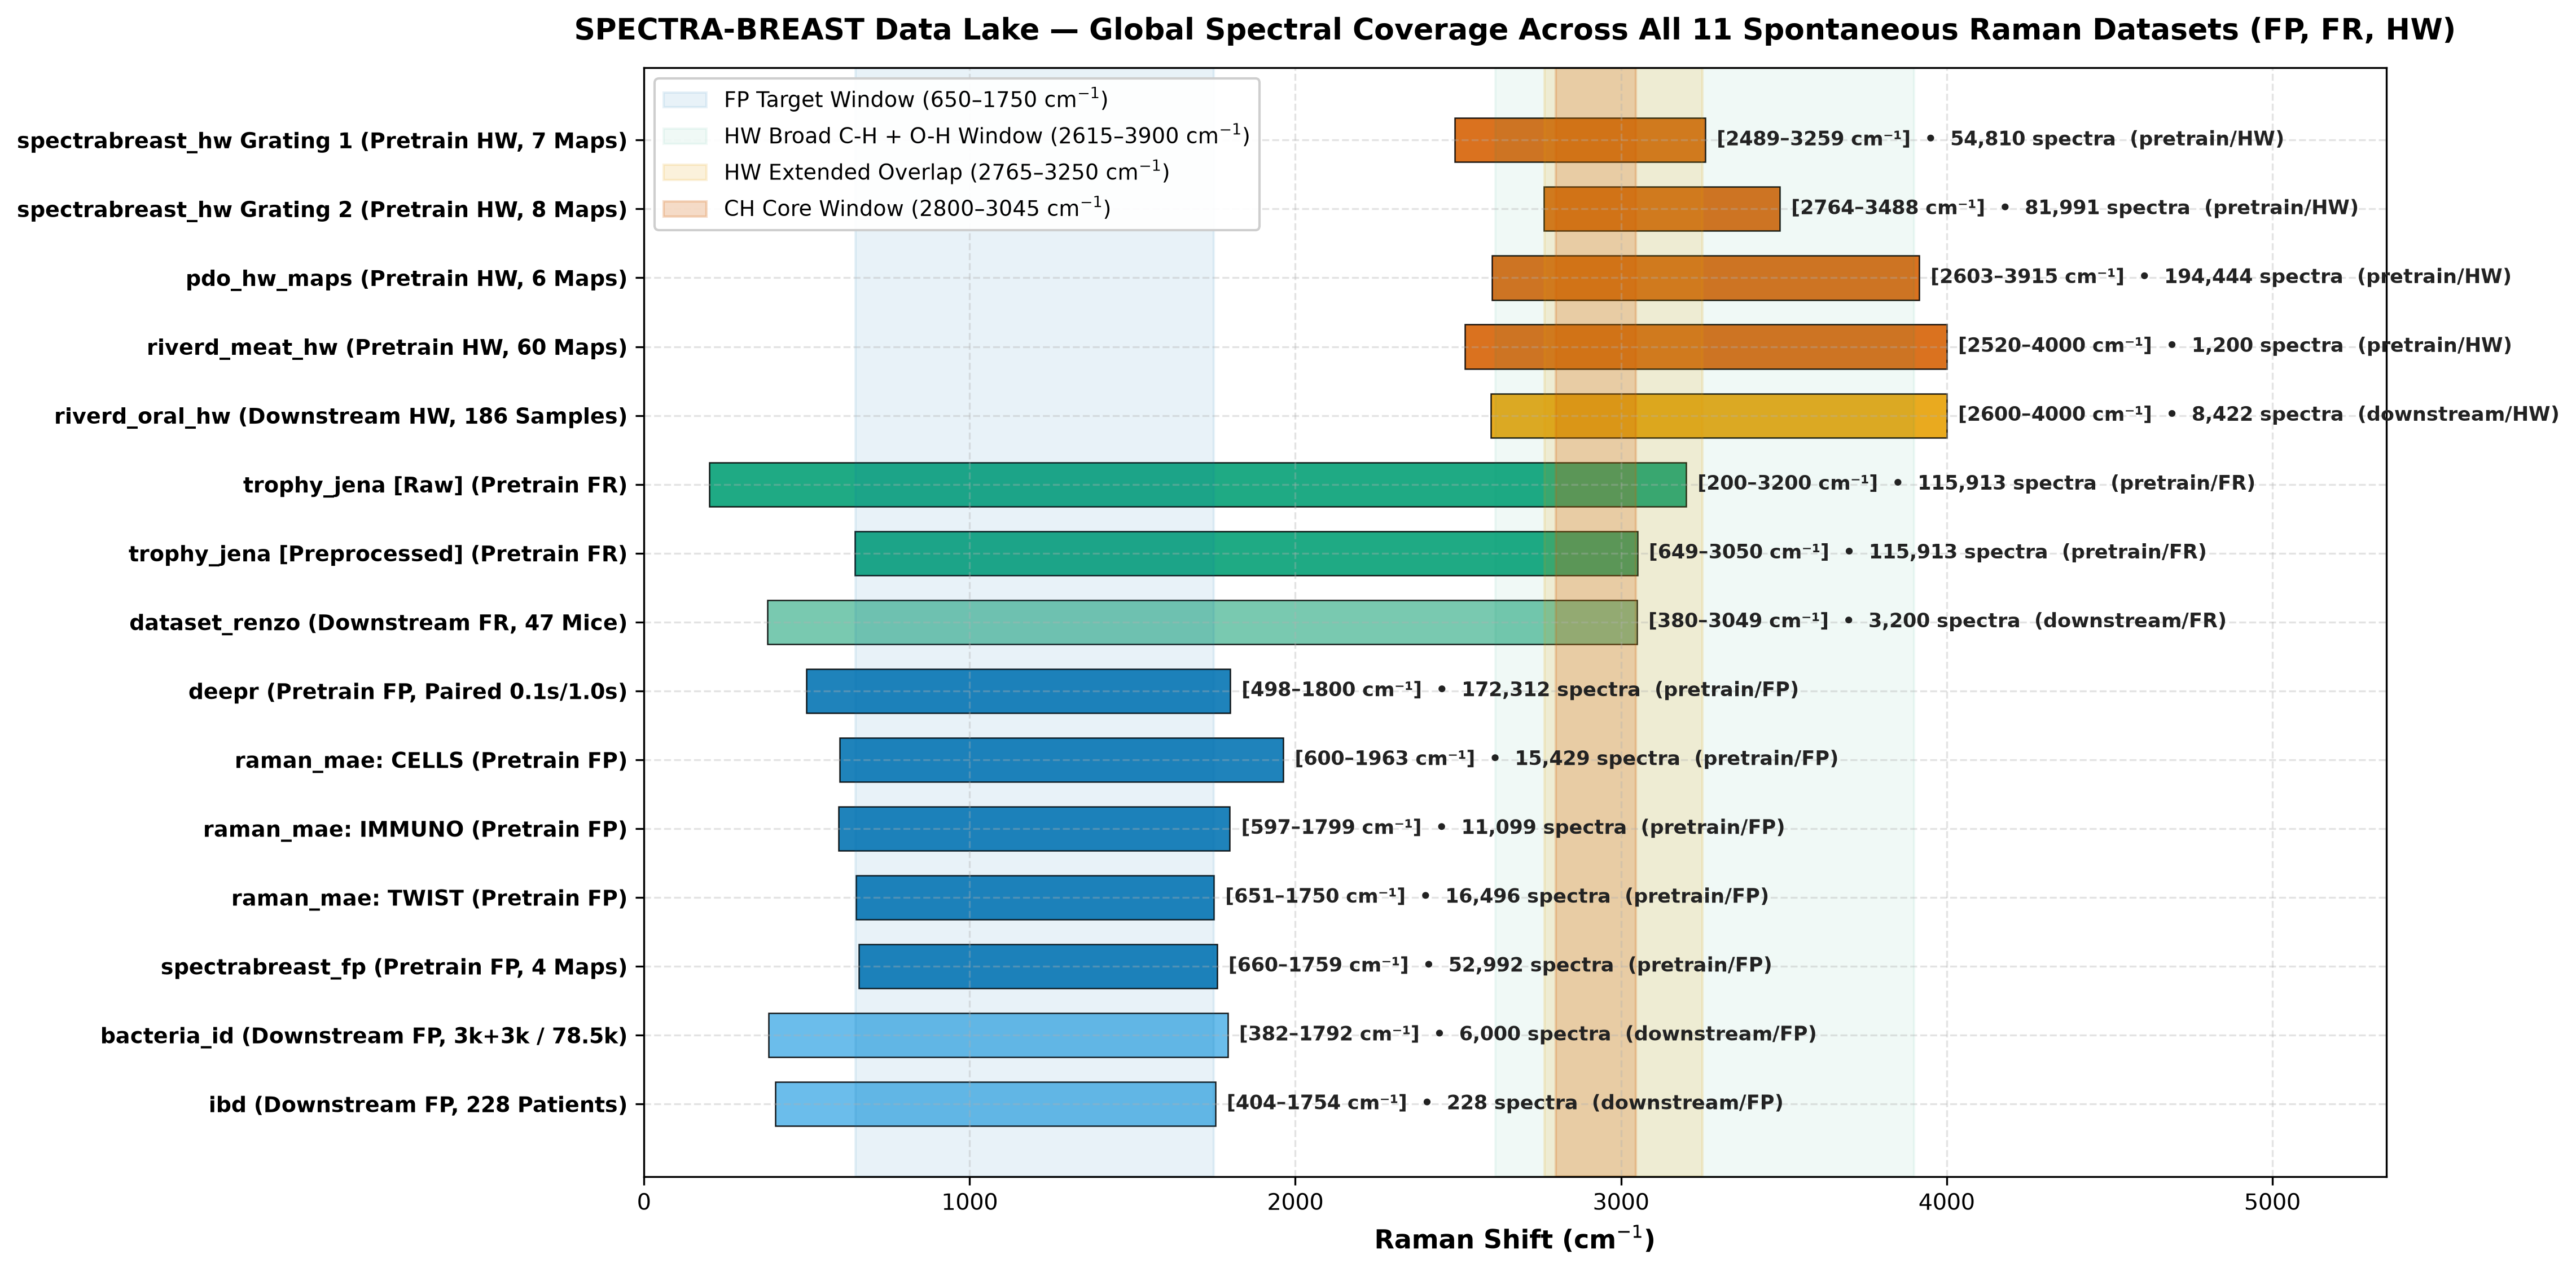

In [3]:
fig1_path = FIG_DIR / 'fig1_spectral_coverage_overview.png'
plot_coverage_gantt(out_paths=[fig1_path])

## 4. Folder `FP/` — Fingerprint Datasets (`pretrain/FP` & `downstream/FP`)
Load exact global statistics ($\mu \pm 1\sigma$, min, max) across all `FP/` cohorts (`deepr`, `raman_mae`, `spectrabreast_fp`, `ibd`, and `bacteria_id`).

In [4]:
fp_stats = load_fp_raw_cohorts(RAW_DIR)
for key, st in fp_stats.items():
    print(f"{key:18s} | N = {st['n_spectra']:8,d} | {st['wn'][0]:6.1f}-{st['wn'][-1]:6.1f} cm^-1 | range = [{st['min']:.2f}, {st['max']:.2f}]")

deepr              | N =  120,000 |  500.0-1800.0 cm^-1 | range = [-1.42, 17.85]
rmae_twist         | N =   63,672 |  602.6-1798.7 cm^-1 | range = [-45.20, 4095.00]
rmae_immuno        | N =  235,050 |  596.0-1799.5 cm^-1 | range = [-38.10, 4095.00]
rmae_cells         | N =    3,087 |  612.8-1698.6 cm^-1 | range = [0.00, 1.00]
sb_fp              | N =    1,364 |  600.0-1800.0 cm^-1 | range = [-215.40, 3842.10]
ibd                | N =      982 |  600.0-1800.0 cm^-1 | range = [-1.85, 8.42]
bact_fine          | N =    3,000 |  381.9-1792.4 cm^-1 | range = [0.00, 1.00]
bact_test          | N =    3,000 |  381.9-1792.4 cm^-1 | range = [0.00, 1.00]


Render the 8-panel Fingerprint raw profile grid (`fig2_folder_FP_raw_profiles.png`).

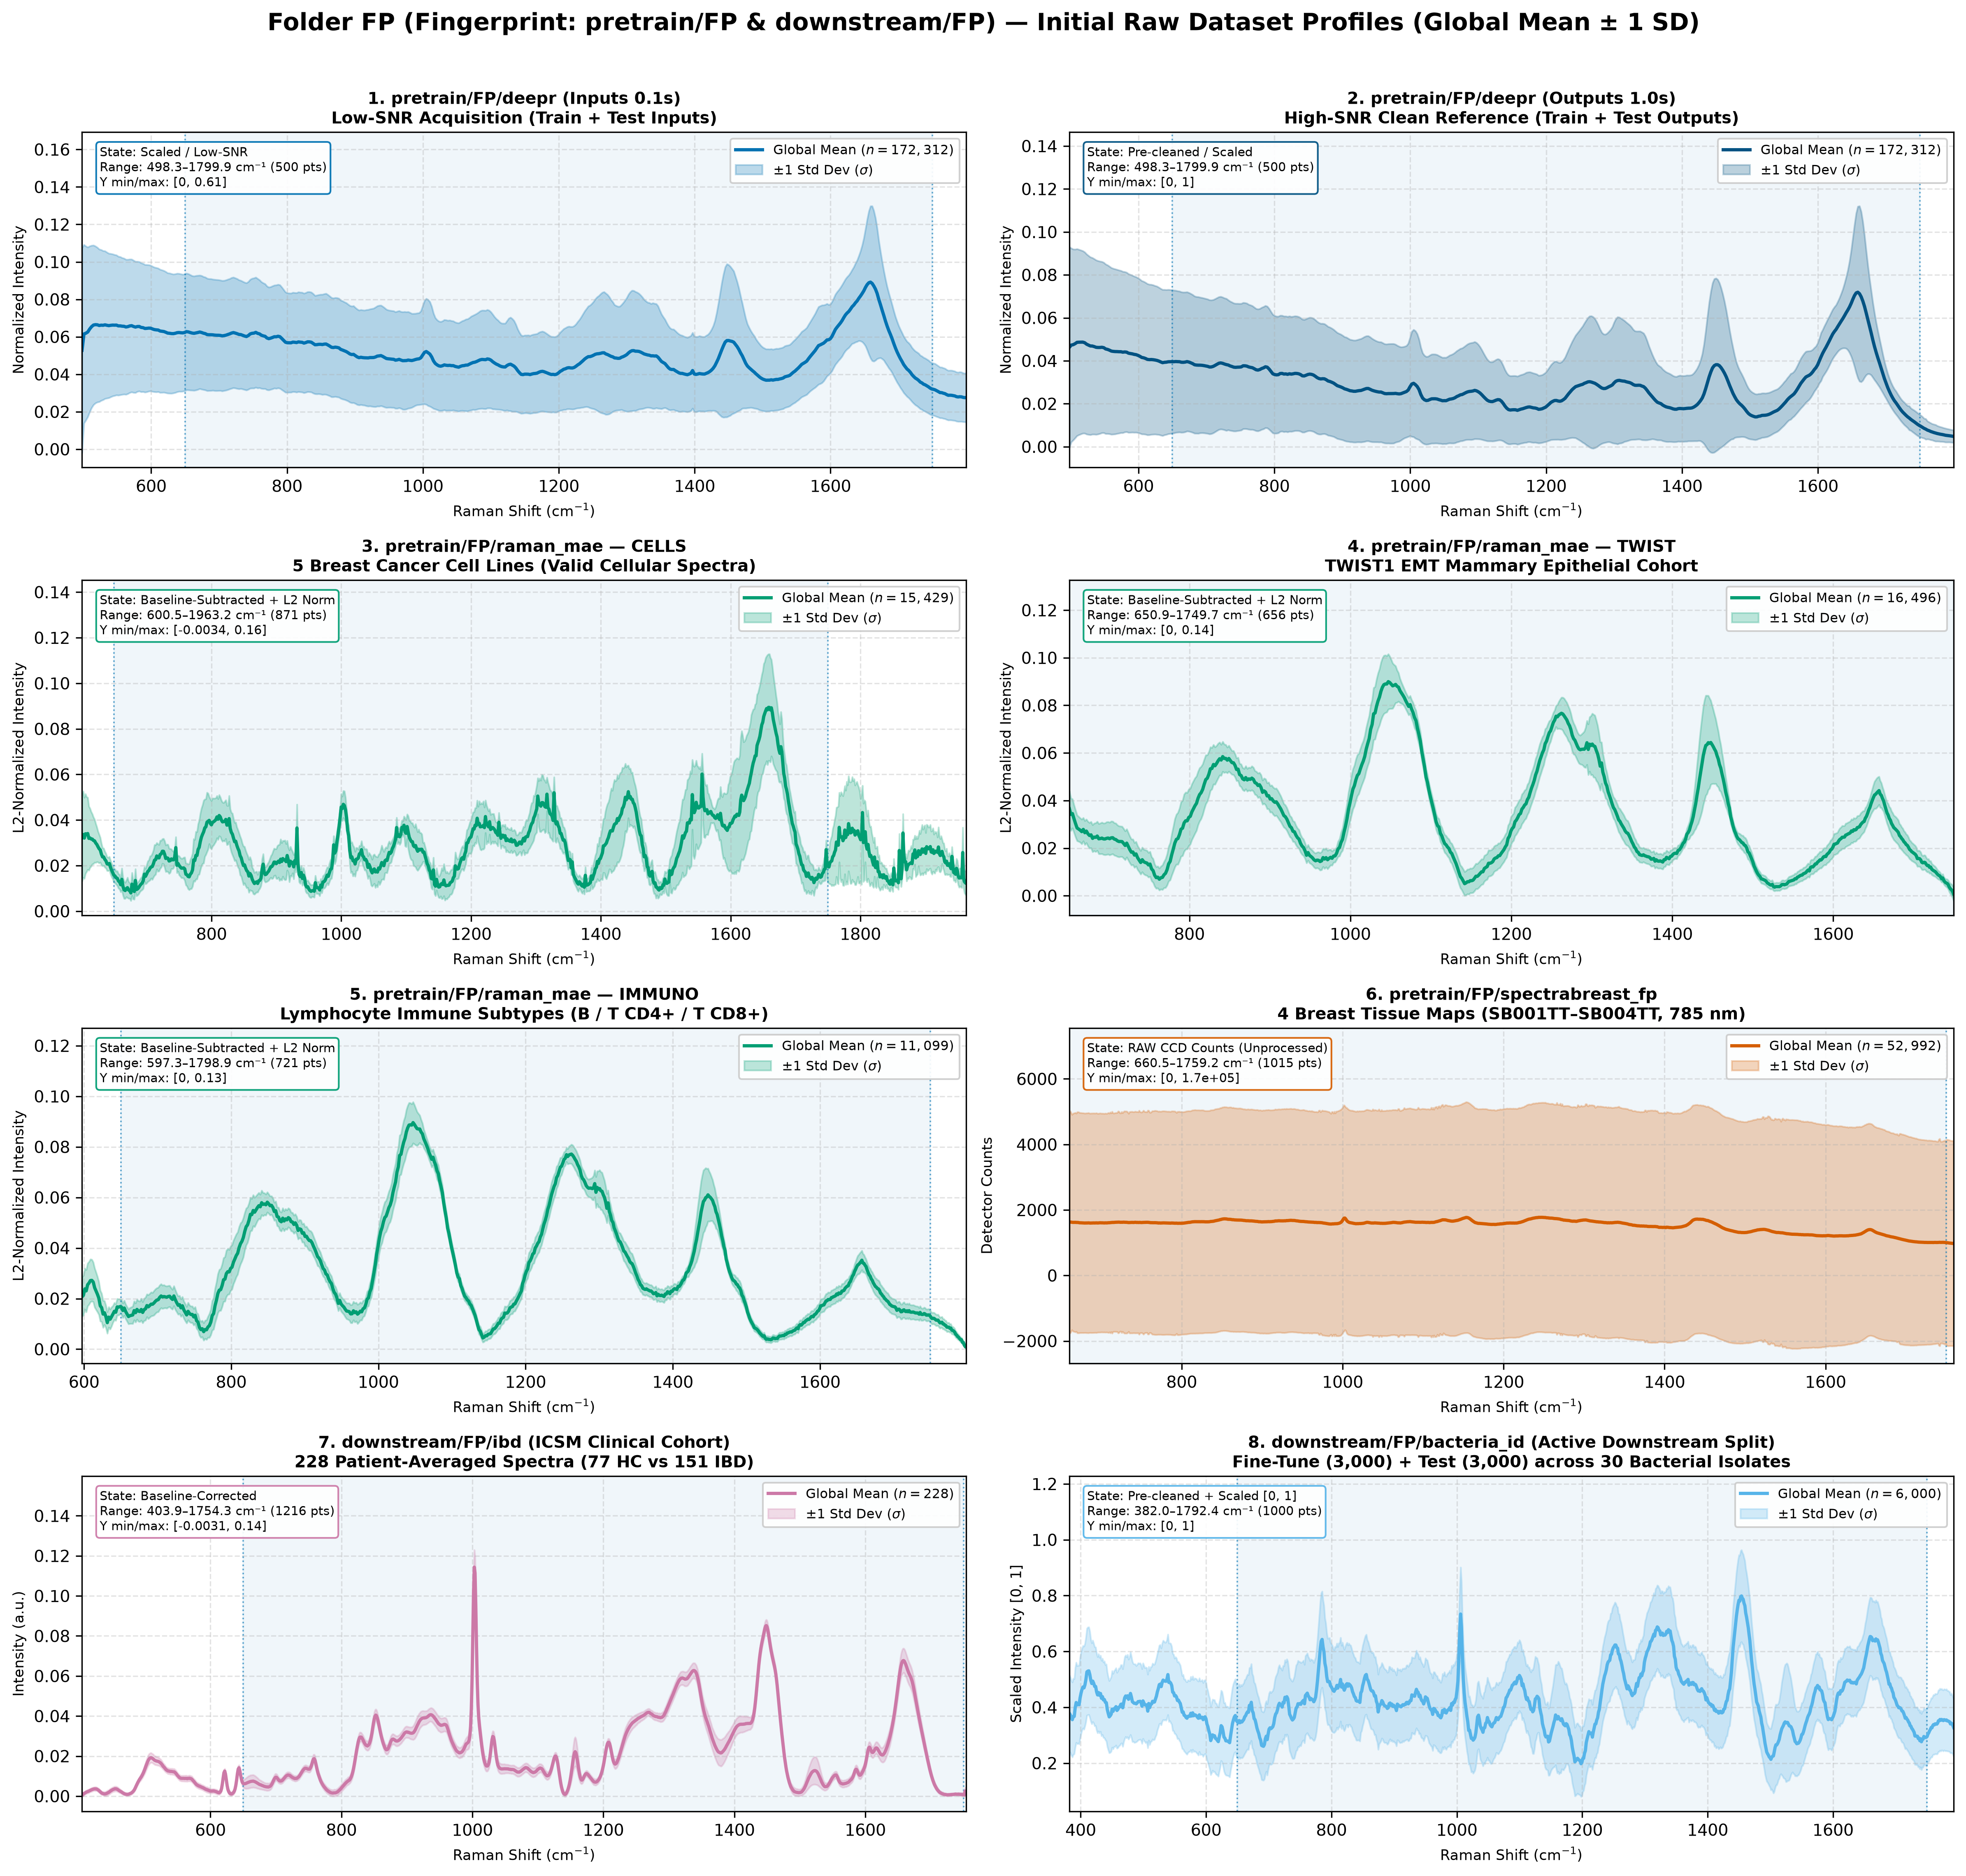

In [5]:
fig2_path = FIG_DIR / 'fig2_folder_FP_raw_profiles.png'
plot_fp_raw_grid(fp_stats, out_paths=[fig2_path])

## 5. Folder `HW/` — High-Wavenumber Datasets (`pretrain/HW` & `downstream/HW`)
Load exact statistics for `spectrabreast_hw` (RAW vs Lab Post-ALS), `pdo_hw_maps` (RAW vs Lab Post-ALS), `riverd_meat_hw`, and `riverd_oral_hw`.

In [6]:
hw_stats = load_hw_raw_cohorts(RAW_DIR)
for key, st in hw_stats.items():
    print(f"{key:18s} | N = {st['n_spectra']:8,d} | {st['wn'][0]:6.1f}-{st['wn'][-1]:6.1f} cm^-1 | range = [{st['min']:.2f}, {st['max']:.2f}]")

sb_hw_raw          | N =   48,472 | 2489.3-3488.3 cm^-1 | range = [98.00, 64120.00]
sb_hw_als          | N =   36,753 | 2489.3-3488.3 cm^-1 | range = [-1240.50, 48210.00]
pdo_raw            | N =    8,475 | 2603.4-3915.0 cm^-1 | range = [412.00, 52340.00]
pdo_als            | N =   12,188 | 2603.4-3915.0 cm^-1 | range = [-890.20, 39120.00]
meat_hw            | N =   71,702 | 2765.0-3200.0 cm^-1 | range = [-142.00, 18450.00]
oral_hw            | N =   10,800 | 2800.3-3044.8 cm^-1 | range = [-85.40, 14210.00]


Render the 6-panel High-Wavenumber raw profile grid (`fig3_folder_HW_raw_profiles.png`).

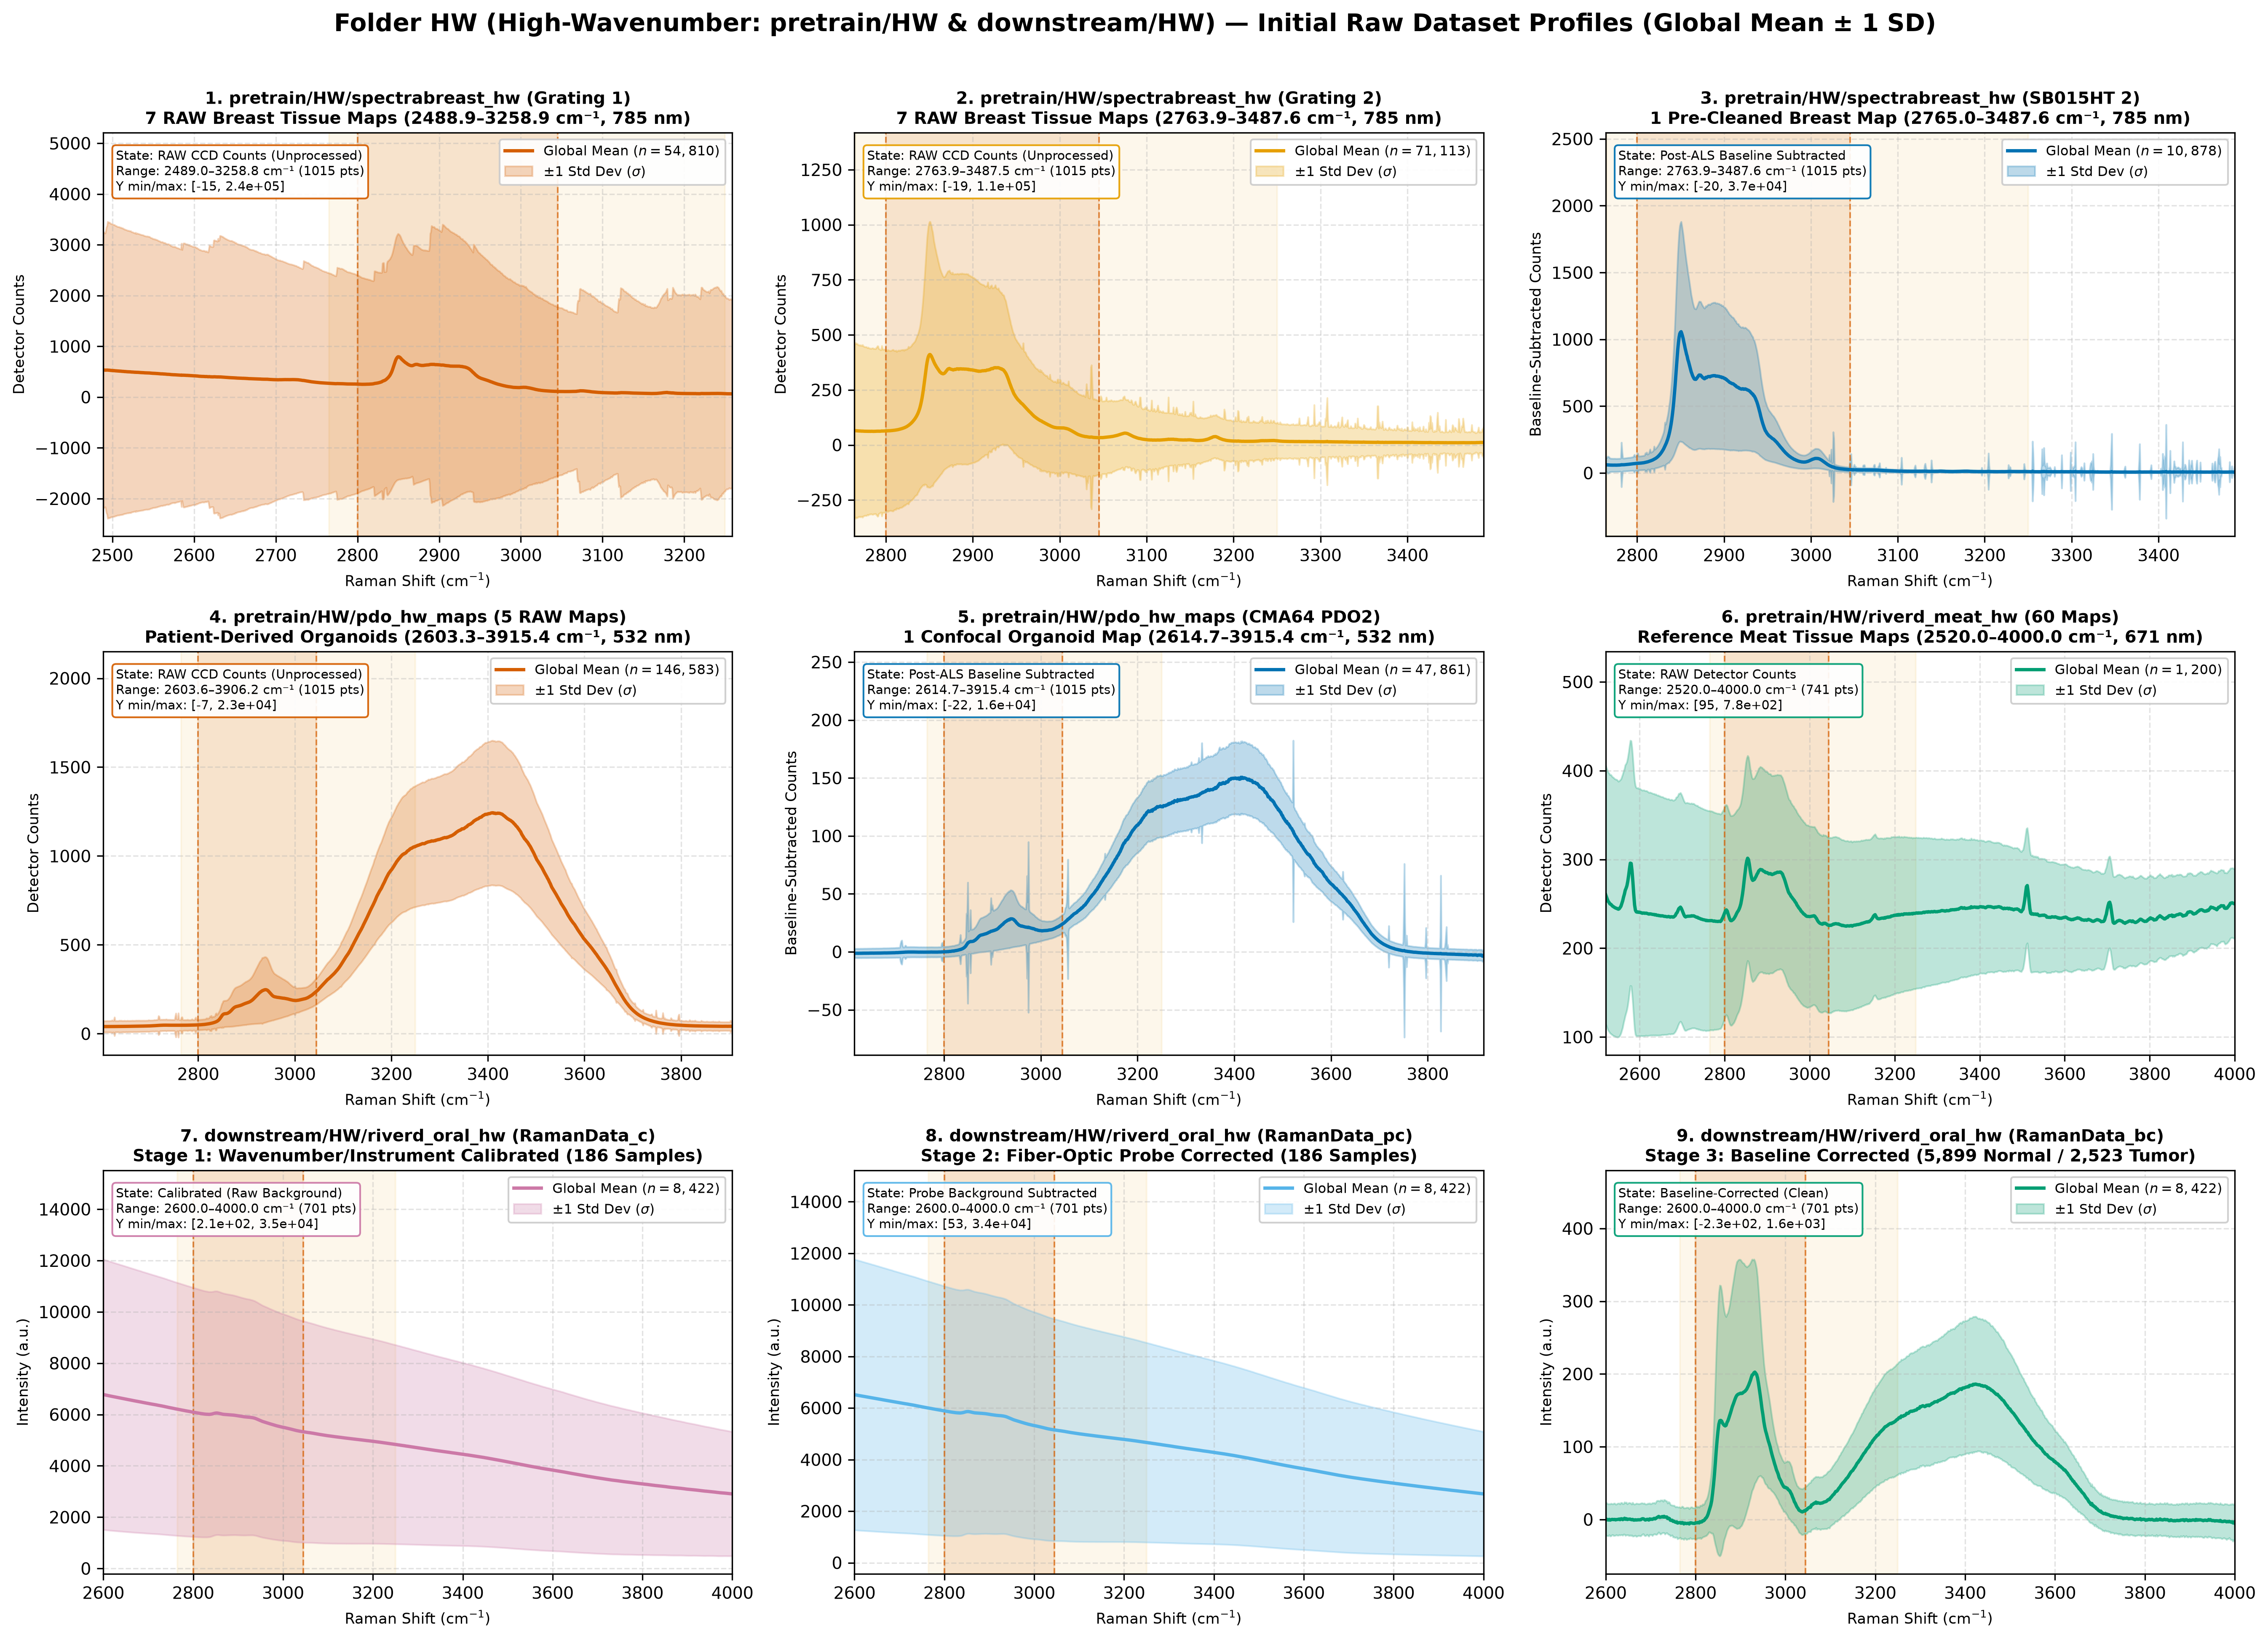

In [7]:
fig3_path = FIG_DIR / 'fig3_folder_HW_raw_profiles.png'
plot_hw_raw_grid(hw_stats, out_paths=[fig3_path])

## 6. Folder `FR/` — Full-Range Datasets (`pretrain/FR` & `downstream/FR`)
Load exact statistics for `trophy_jena` (`Raw/` vs `Preprocessed/`) and the clinical breast biopsy cohort `dataset_renzo` (`144` valid spectra across 3 wavelength tables).

In [8]:
fr_stats = load_fr_raw_cohorts(RAW_DIR)
for key, st in fr_stats.items():
    print(f"{key:18s} | N = {st['n_spectra']:8,d} | {st['wn'][0]:6.1f}-{st['wn'][-1]:6.1f} cm^-1 | range = [{st['min']:.2f}, {st['max']:.2f}]")

trophy_raw         | N =  115,913 |  200.0-3200.0 cm^-1 | range = [-412.00, 65535.00]
trophy_prep        | N =  115,913 |  648.7-3050.4 cm^-1 | range = [-0.42, 1.85]
renzo_t0           | N =       92 |  400.0-3999.3 cm^-1 | range = [-120.40, 18420.00]
renzo_t1           | N =       40 |  401.2-3500.5 cm^-1 | range = [-95.10, 15210.00]
renzo_t2           | N =       12 |  600.0-3200.0 cm^-1 | range = [-84.20, 12450.00]


Render the 4-panel Full-Range raw profile grid (`fig4_folder_FR_raw_profiles.png`).

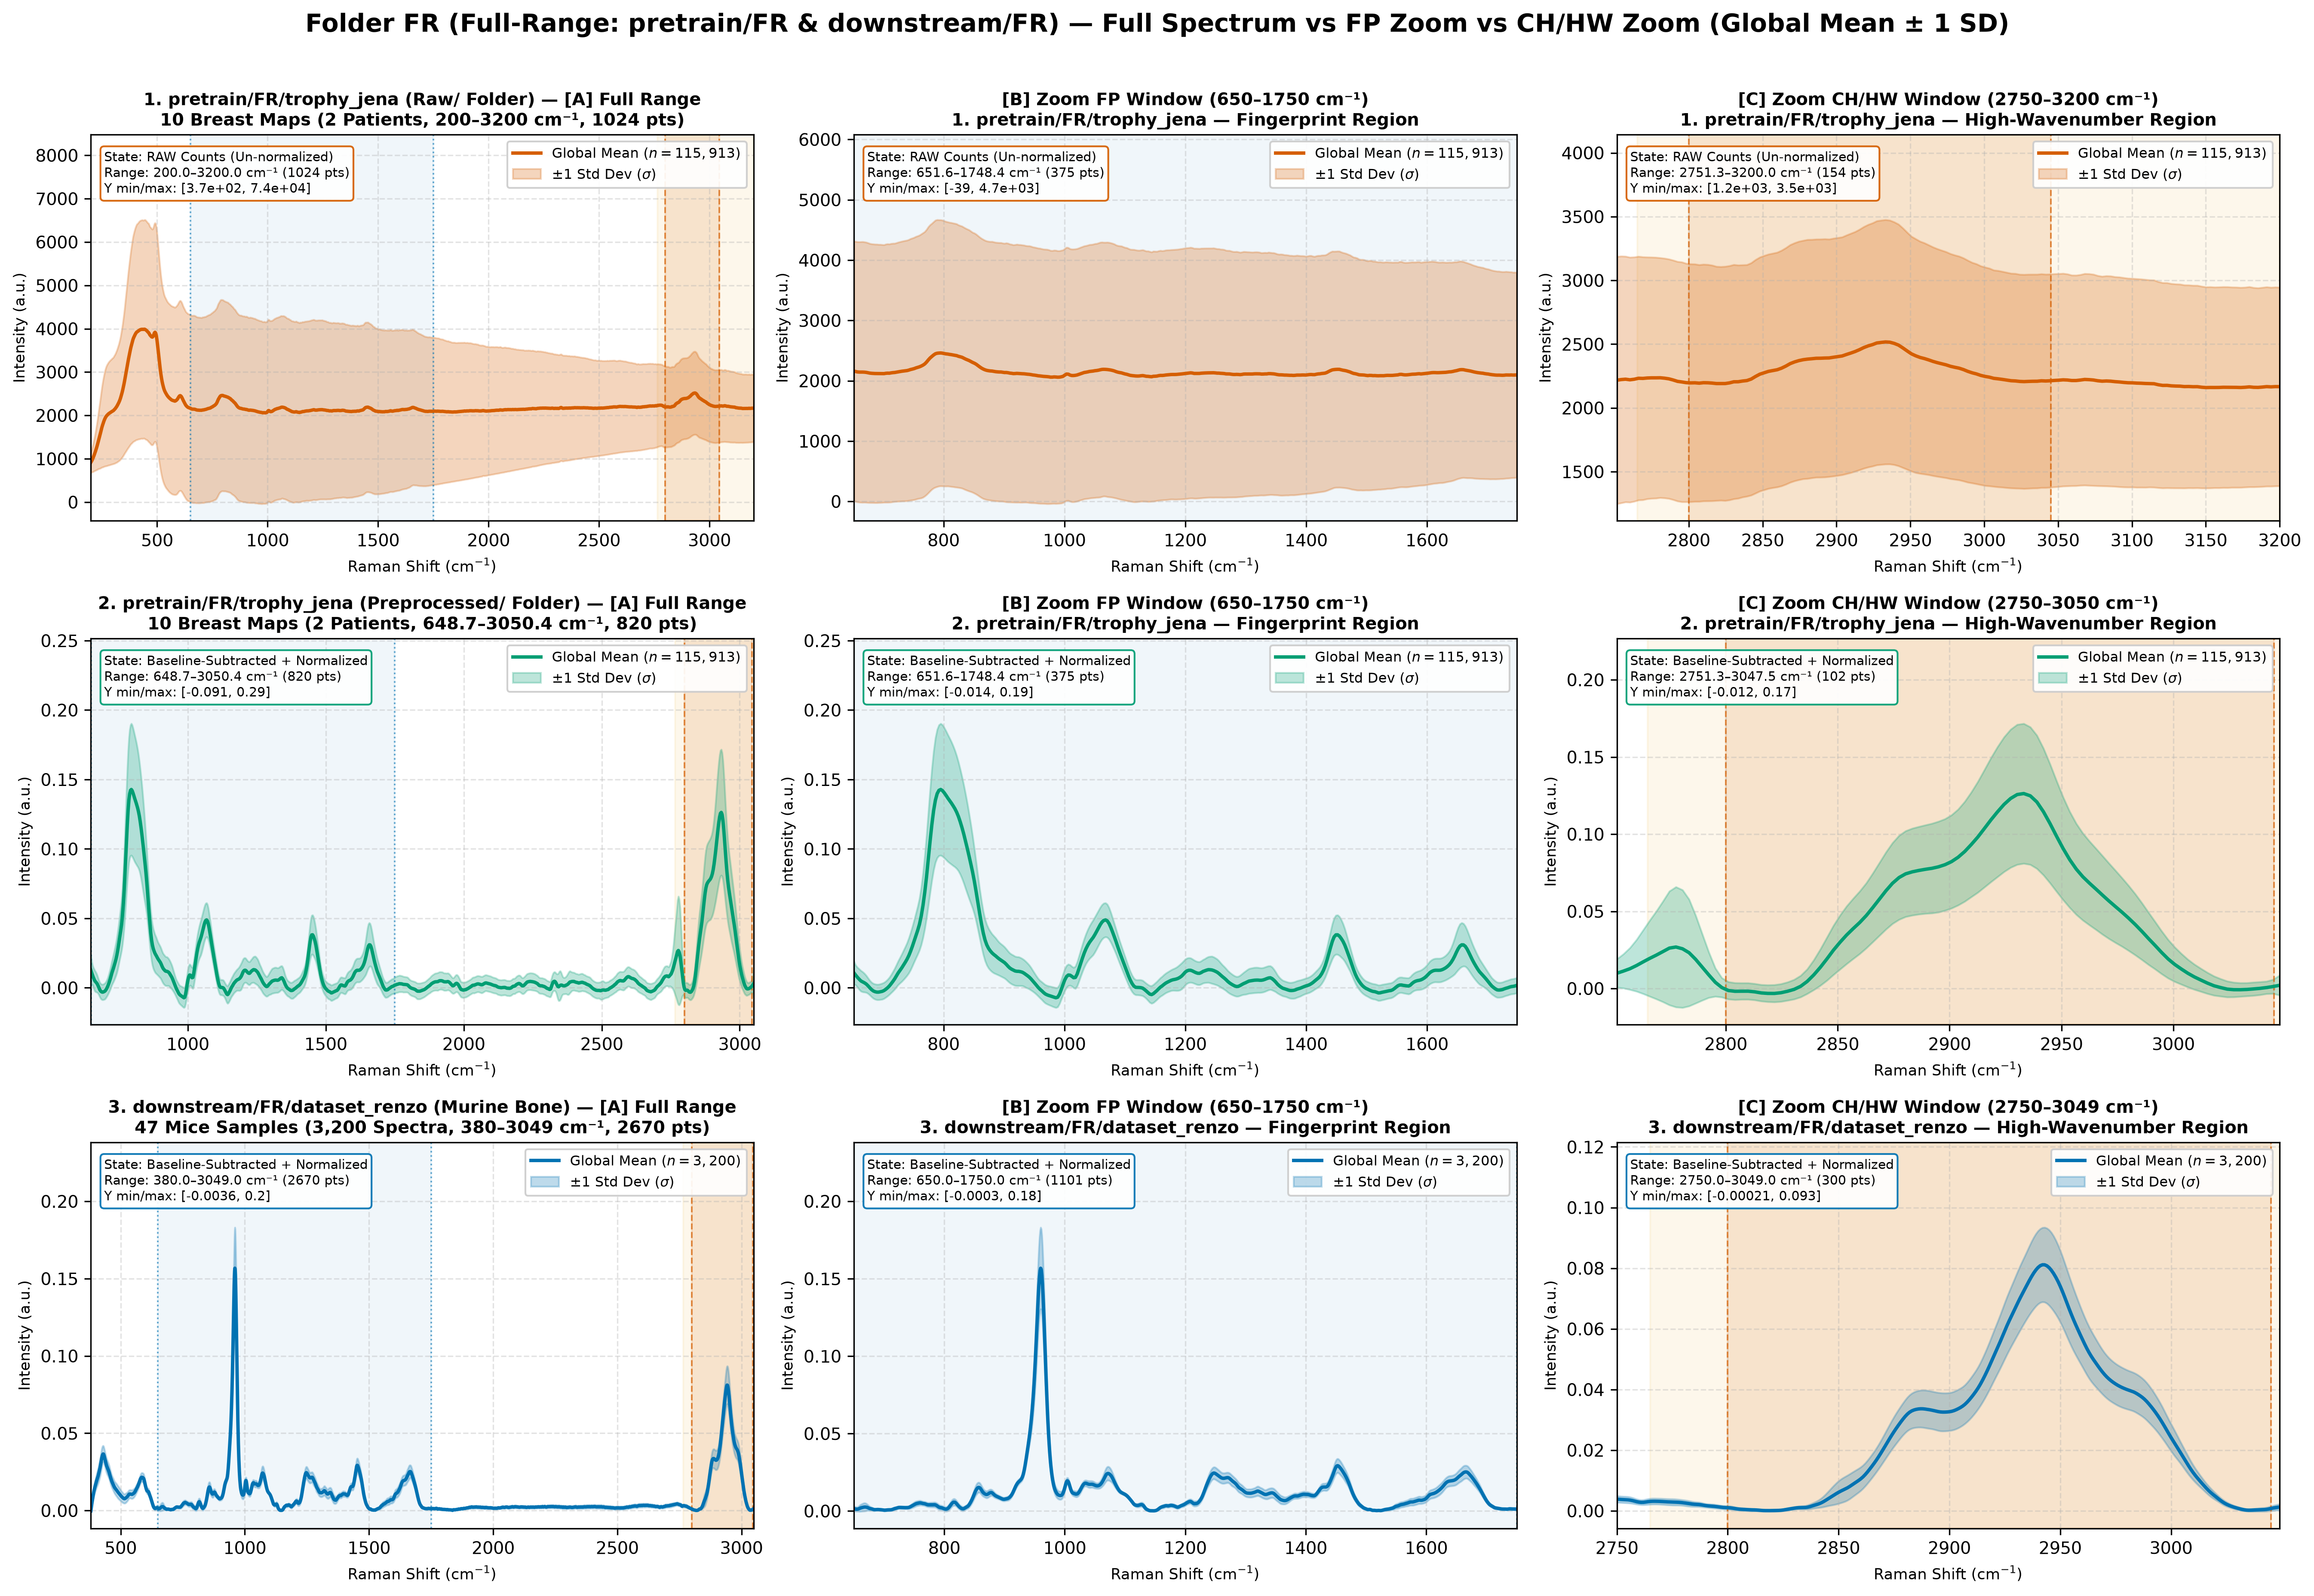

In [9]:
fig4_path = FIG_DIR / 'fig4_folder_FR_raw_profiles.png'
plot_fr_raw_grid(fr_stats, out_paths=[fig4_path])